# **Used Car Price Prediction**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## **Data Exploration(Before Preprocessing)**

In [2]:
#loading the dataset
df=pd.read_csv('dataset.csv')
df.head()

,Unnamed: 0,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,New_Price,Price
0,0,Maruti Wagon R LXI CNG,Mumbai,2010,72000,CNG,Manual,First,26.6 km/kg,998 CC,58.16 bhp,5.0,NaN,1.75
1,1,Hyundai Creta 1.6 CRDi SX Option,Pune,2015,41000,Diesel,Manual,First,19.67 kmpl,1582 CC,126.2 bhp,5.0,NaN,12.50
2,2,Honda Jazz V,Chennai,2011,46000,Petrol,Manual,First,18.2 kmpl,1199 CC,88.7 bhp,5.0,8.61 Lakh,4.50
3,3,Maruti Ertiga VDI,Chennai,2012,87000,Diesel,Manual,First,20.77 kmpl,1248 CC,88.76 bhp,7.0,NaN,6.00
4,4,Audi A4 New 2.0 TDI Multitronic,Coimbatore,2013,40670,Diesel,Automatic,Second,15.2 kmpl,1968 CC,140.8 bhp,5.0,NaN,17.74


### **Understanding the Dataset**

In [3]:
df.shape

(6019, 14)

In [4]:
#getting some info about data
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6019 entries, 0 to 6018
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         6019 non-null   int64  
 1   Name               6019 non-null   str    
 2   Location           6019 non-null   str    
 3   Year               6019 non-null   int64  
 4   Kilometers_Driven  6019 non-null   int64  
 5   Fuel_Type          6019 non-null   str    
 6   Transmission       6019 non-null   str    
 7   Owner_Type         6019 non-null   str    
 8   Mileage            6017 non-null   str    
 9   Engine             5983 non-null   str    
 10  Power              5983 non-null   str    
 11  Seats              5977 non-null   float64
 12  New_Price          824 non-null    str    
 13  Price              6019 non-null   float64
dtypes: float64(2), int64(3), str(9)
memory usage: 658.5 KB


In [5]:
#getting the statistical summary of Data Frame
df.describe()

,Unnamed: 0,Year,Kilometers_Driven,Seats,Price
count,6019.000000,6019.000000,6.019000e+03,5977.000000,6019.000000
mean,3009.000000,2013.358199,5.873838e+04,5.278735,9.479468
std,1737.679967,3.269742,9.126884e+04,0.808840,11.187917
min,0.000000,1998.000000,1.710000e+02,0.000000,0.440000
25%,1504.500000,2011.000000,3.400000e+04,5.000000,3.500000
50%,3009.000000,2014.000000,5.300000e+04,5.000000,5.640000
75%,4513.500000,2016.000000,7.300000e+04,5.000000,9.950000
max,6018.000000,2019.000000,6.500000e+06,10.000000,160.000000


In [6]:
#checking no of missing values in each column
print(df.isnull().sum())

Unnamed: 0              0
Name                    0
Location                0
Year                    0
Kilometers_Driven       0
Fuel_Type               0
Transmission            0
Owner_Type              0
Mileage                 2
Engine                 36
Power                  36
Seats                  42
New_Price            5195
Price                   0
dtype: int64


In [7]:
#checking no of duplicate rows
print(df.duplicated().sum())

0


### **Univariate Analysis**

In [8]:
# no of unique values in column 'Name'
print(df['Name'].value_counts())

Name
Mahindra XUV500 W8 2WD                        49
Maruti Swift VDI                              45
Honda City 1.5 S MT                           34
Maruti Swift Dzire VDI                        34
Maruti Swift VDI BSIV                         31
                                              ..
Hyundai Elantra SX                             1
Maruti Wagon R Duo Lxi                         1
Volkswagen Polo IPL II 1.2 Petrol Highline     1
Tata Bolt Revotron XT                          1
Mahindra Xylo D4 BSIV                          1
Name: count, Length: 1876, dtype: int64


As it appears, there are several cars in the dataset, some of them with a count higher than 1. Sometimes the resale value of a car also depends on manufacturer of car and hence, I'll extract the manufacturer from this column and add it to the dataset. I'll do it later on Data processing part

In [9]:
# no of unique values in column 'Fuel_Type'
print(df['Location'].value_counts())

Location
Mumbai        790
Hyderabad     742
Kochi         651
Coimbatore    636
Pune          622
Delhi         554
Kolkata       535
Chennai       494
Jaipur        413
Bangalore     358
Ahmedabad     224
Name: count, dtype: int64


In [10]:
# no of unique values in column 'Fuel_Type'
print(df['Fuel_Type'].value_counts())

Fuel_Type
Diesel      3205
Petrol      2746
CNG           56
LPG           10
Electric       2
Name: count, dtype: int64


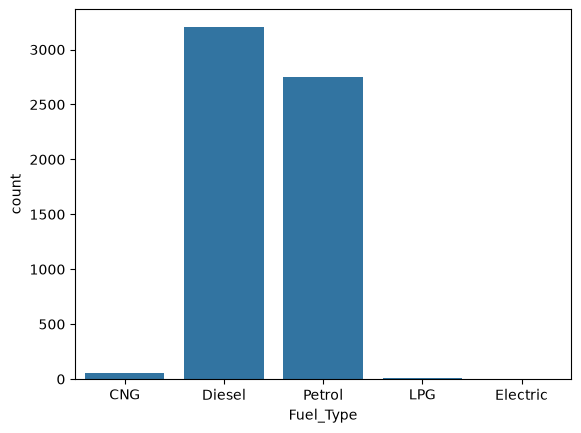

In [11]:
# count plot on Fuel Type
sns.countplot(x ='Fuel_Type', data = df)
plt.show()

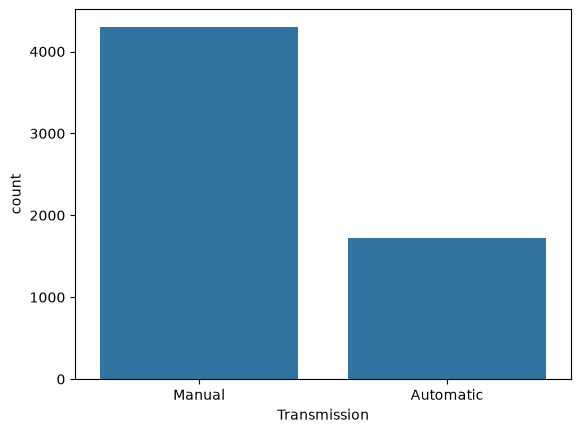

In [12]:
# count plot on Transmission
sns.countplot(x ='Transmission', data = df)
plt.show()

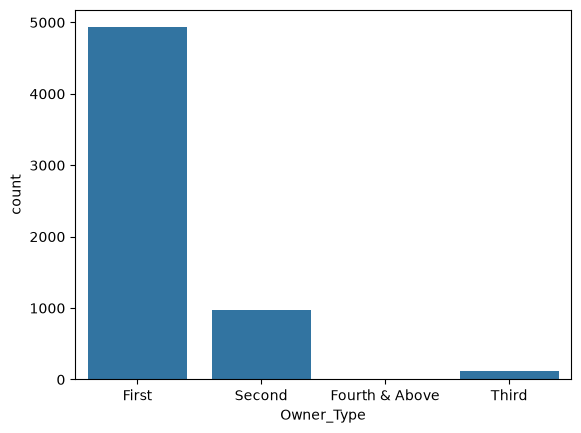

In [13]:
# count plot on Owner_Type
sns.countplot(x ='Owner_Type', data = df)
plt.show()

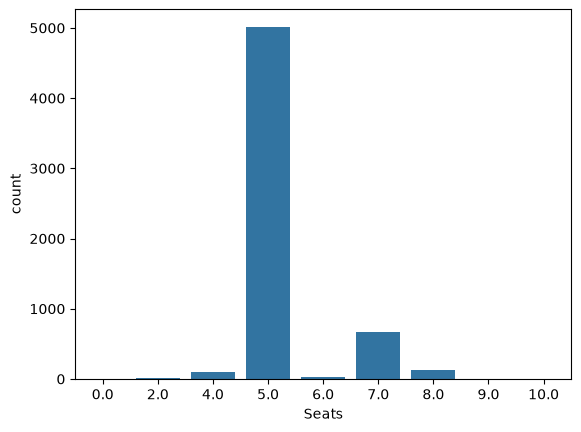

In [14]:
# count plot on Seats
sns.countplot(x ='Seats', data = df)
plt.show()

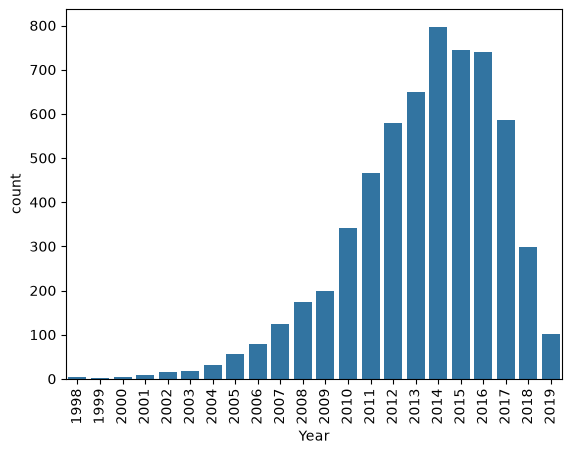

In [15]:
# count plot on Year
sns.countplot(x ='Year', data = df)
plt.xticks(rotation=90)
plt.show()

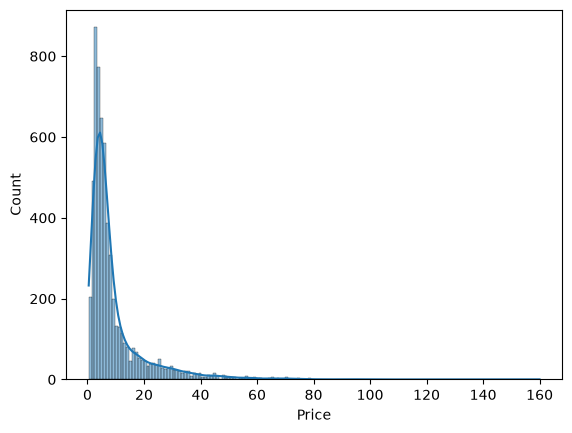

In [16]:
#histogram for Price
sns.histplot(data = df, x = 'Price', kde=True)
plt.show()

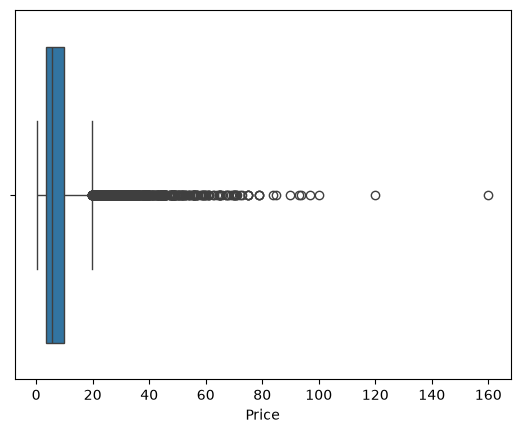

In [17]:
#Horizontal Boxplot of Price
sns.boxplot(x="Price", data=df)
plt.show()

The data type of "Mileage", "Engine" and "Power" need to be fixed so we will visualize it later	

### **Bivariate Analysis**

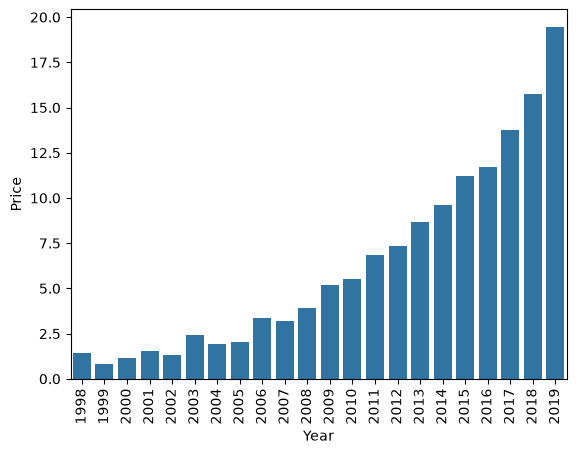

In [18]:
# Price vs year
#barplot without error bar
sns.barplot(x = 'Year', y = 'Price', data = df, errorbar=None)
plt.xticks(rotation=90)
plt.show()

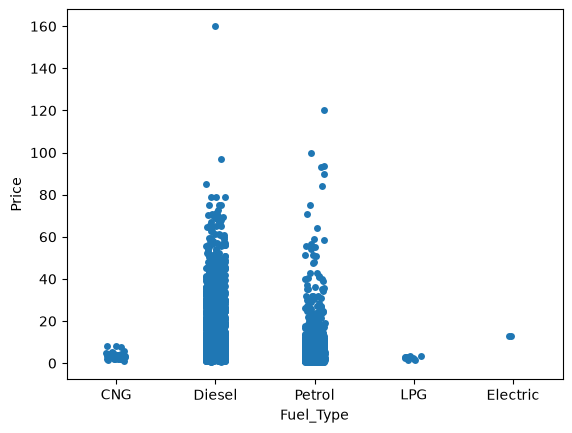

In [19]:
#price vs Fuel Type
#basic strip plot
sns.stripplot(data=df, x="Fuel_Type", y="Price")
plt.show()

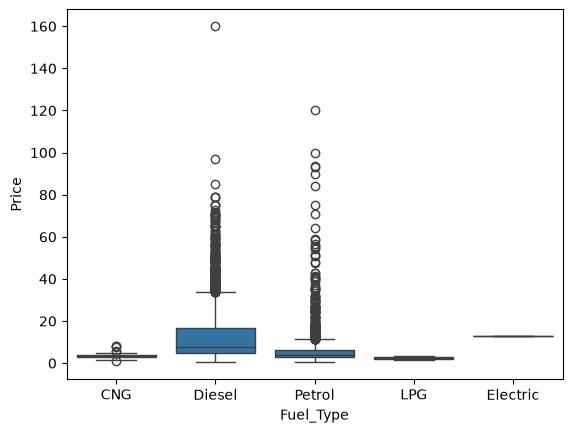

In [20]:
# price vs Fuel Type
#box plots wrt Fuel Type
sns.boxplot(x="Fuel_Type", y="Price", data=df)
plt.show()

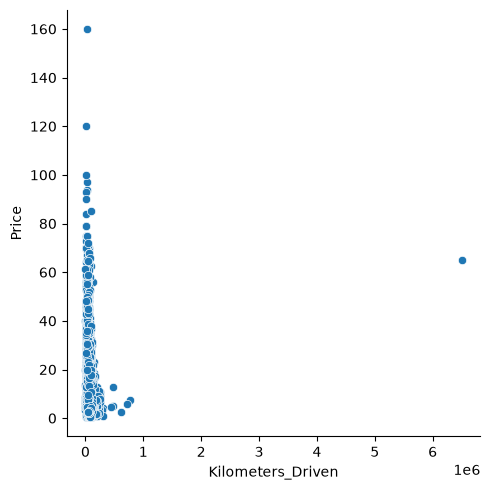

In [21]:
#Kilometers_Driven vs Price
#simple scatter plot showing relation between Kilometers_Driven and Price
sns.relplot(x='Kilometers_Driven', y='Price', data=df)
plt.show()

## **Data PreProcessing**

### **Correcting Data Types**

In [22]:
#viewing data types of each column
print(df.dtypes)

Unnamed: 0             int64
Name                     str
Location                 str
Year                   int64
Kilometers_Driven      int64
Fuel_Type                str
Transmission             str
Owner_Type               str
Mileage                  str
Engine                   str
Power                    str
Seats                float64
New_Price                str
Price                float64
dtype: object


In [23]:
(df['Power'] == 'null bhp').sum()

np.int64(107)

In [24]:
df['Power'] = df['Power'].replace('null bhp',None)

In [25]:
#extracting numerical value out of mileage
mileage = df["Mileage"].str.split(" ", expand = True)
df["Mileage"] = mileage[0]

#extracting numerical value out of Engine 
engine = df["Engine"].str.split(" ", expand = True)
df["Engine"] = engine[0]

#extracting numerical value out of Power 
power = df["Power"].str.split(" ", expand = True)
df["Power"] = power[0]

df.head()

,Unnamed: 0,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,New_Price,Price
0,0,Maruti Wagon R LXI CNG,Mumbai,2010,72000,CNG,Manual,First,26.6,998,58.16,5.0,NaN,1.75
1,1,Hyundai Creta 1.6 CRDi SX Option,Pune,2015,41000,Diesel,Manual,First,19.67,1582,126.2,5.0,NaN,12.50
2,2,Honda Jazz V,Chennai,2011,46000,Petrol,Manual,First,18.2,1199,88.7,5.0,8.61 Lakh,4.50
3,3,Maruti Ertiga VDI,Chennai,2012,87000,Diesel,Manual,First,20.77,1248,88.76,7.0,NaN,6.00
4,4,Audi A4 New 2.0 TDI Multitronic,Coimbatore,2013,40670,Diesel,Automatic,Second,15.2,1968,140.8,5.0,NaN,17.74


In [26]:
# Convert from string to numeric
df['Mileage'] = pd.to_numeric(df['Mileage'],errors = 'coerce')
df['Engine'] = pd.to_numeric(df['Engine'],errors = 'coerce')
df['Power'] = pd.to_numeric(df['Power'],errors = 'coerce')
print(df.dtypes)


Unnamed: 0             int64
Name                     str
Location                 str
Year                   int64
Kilometers_Driven      int64
Fuel_Type                str
Transmission             str
Owner_Type               str
Mileage              float64
Engine               float64
Power                float64
Seats                float64
New_Price                str
Price                float64
dtype: object


### **Handling Missing Values**

In [27]:
#checking no of missing values in each column
print(df.isnull().sum())

Unnamed: 0              0
Name                    0
Location                0
Year                    0
Kilometers_Driven       0
Fuel_Type               0
Transmission            0
Owner_Type              0
Mileage                 2
Engine                 36
Power                 143
Seats                  42
New_Price            5195
Price                   0
dtype: int64


Since most of the values of column "New_Price" are missing. We will drop this column

In [28]:
#dropping the column New_Price
df = df.drop(columns='New_Price')
df.head()

,Unnamed: 0,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,Price
0,0,Maruti Wagon R LXI CNG,Mumbai,2010,72000,CNG,Manual,First,26.60,998.0,58.16,5.0,1.75
1,1,Hyundai Creta 1.6 CRDi SX Option,Pune,2015,41000,Diesel,Manual,First,19.67,1582.0,126.20,5.0,12.50
2,2,Honda Jazz V,Chennai,2011,46000,Petrol,Manual,First,18.20,1199.0,88.70,5.0,4.50
3,3,Maruti Ertiga VDI,Chennai,2012,87000,Diesel,Manual,First,20.77,1248.0,88.76,7.0,6.00
4,4,Audi A4 New 2.0 TDI Multitronic,Coimbatore,2013,40670,Diesel,Automatic,Second,15.20,1968.0,140.80,5.0,17.74


In [29]:
#filling the column "Mileage","Engine" and "Power" with mean

mean_mileage = df["Mileage"].mean()
df.fillna({"Mileage": mean_mileage}, inplace=True)

mean_engine = df["Engine"].mean()
df.fillna({"Engine": mean_engine}, inplace=True)

mean_power = df["Power"].mean()
df.fillna({"Power": mean_power}, inplace=True)

print(df.isnull().sum())

Unnamed: 0            0
Name                  0
Location              0
Year                  0
Kilometers_Driven     0
Fuel_Type             0
Transmission          0
Owner_Type            0
Mileage               0
Engine                0
Power                 0
Seats                42
Price                 0
dtype: int64


In [30]:
#filling the column "Seats" with mode
mode_seats = df["Seats"].mode()
df.fillna({"Seats": mode_seats[0]}, inplace=True)
print(df.isnull().sum())

Unnamed: 0           0
Name                 0
Location             0
Year                 0
Kilometers_Driven    0
Fuel_Type            0
Transmission         0
Owner_Type           0
Mileage              0
Engine               0
Power                0
Seats                0
Price                0
dtype: int64


### **Handling Duplicates**

In [31]:
#checking no of duplicate rows
print(df.duplicated().sum())

0


Since there are no any duplicates we dont neew to worry about duplicates

### **Removing Outliers**

In [32]:
for col in ['Engine','Power','Kilometers_Driven','Mileage','Price']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 2.5*IQR
    upper_bound = Q3 + 2.5*IQR
    df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]

## **Feature Engineering**

### **Feature Extraction**

We can notice that the 1st word in car name represents manufacturer. So we extract manufacturer name form car name

In [33]:
#extracting the manufacturer name from car name and saving into new column
name = df["Name"].str.split(" ", expand = True)
df["Manufacturer"] = name[0]
df.head()

,Unnamed: 0,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,Price,Manufacturer
0,0,Maruti Wagon R LXI CNG,Mumbai,2010,72000,CNG,Manual,First,26.60,998.0,58.16,5.0,1.75,Maruti
1,1,Hyundai Creta 1.6 CRDi SX Option,Pune,2015,41000,Diesel,Manual,First,19.67,1582.0,126.20,5.0,12.50,Hyundai
2,2,Honda Jazz V,Chennai,2011,46000,Petrol,Manual,First,18.20,1199.0,88.70,5.0,4.50,Honda
3,3,Maruti Ertiga VDI,Chennai,2012,87000,Diesel,Manual,First,20.77,1248.0,88.76,7.0,6.00,Maruti
4,4,Audi A4 New 2.0 TDI Multitronic,Coimbatore,2013,40670,Diesel,Automatic,Second,15.20,1968.0,140.80,5.0,17.74,Audi


### **Exploring Data Once Again**

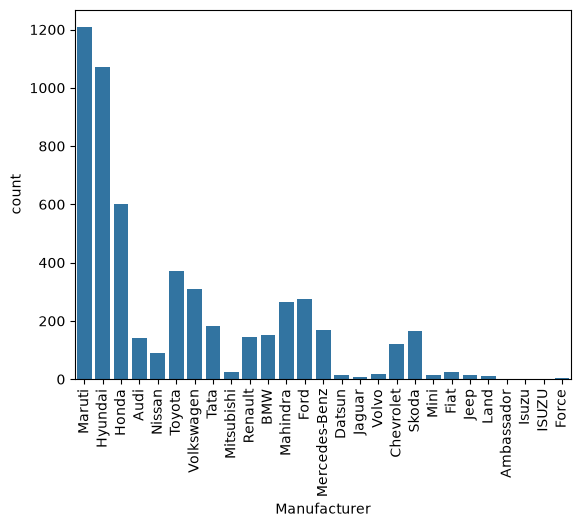

In [34]:
# count plot based on manufacturer
sns.countplot(x ='Manufacturer', data = df)
plt.xticks(rotation=90)
plt.show()

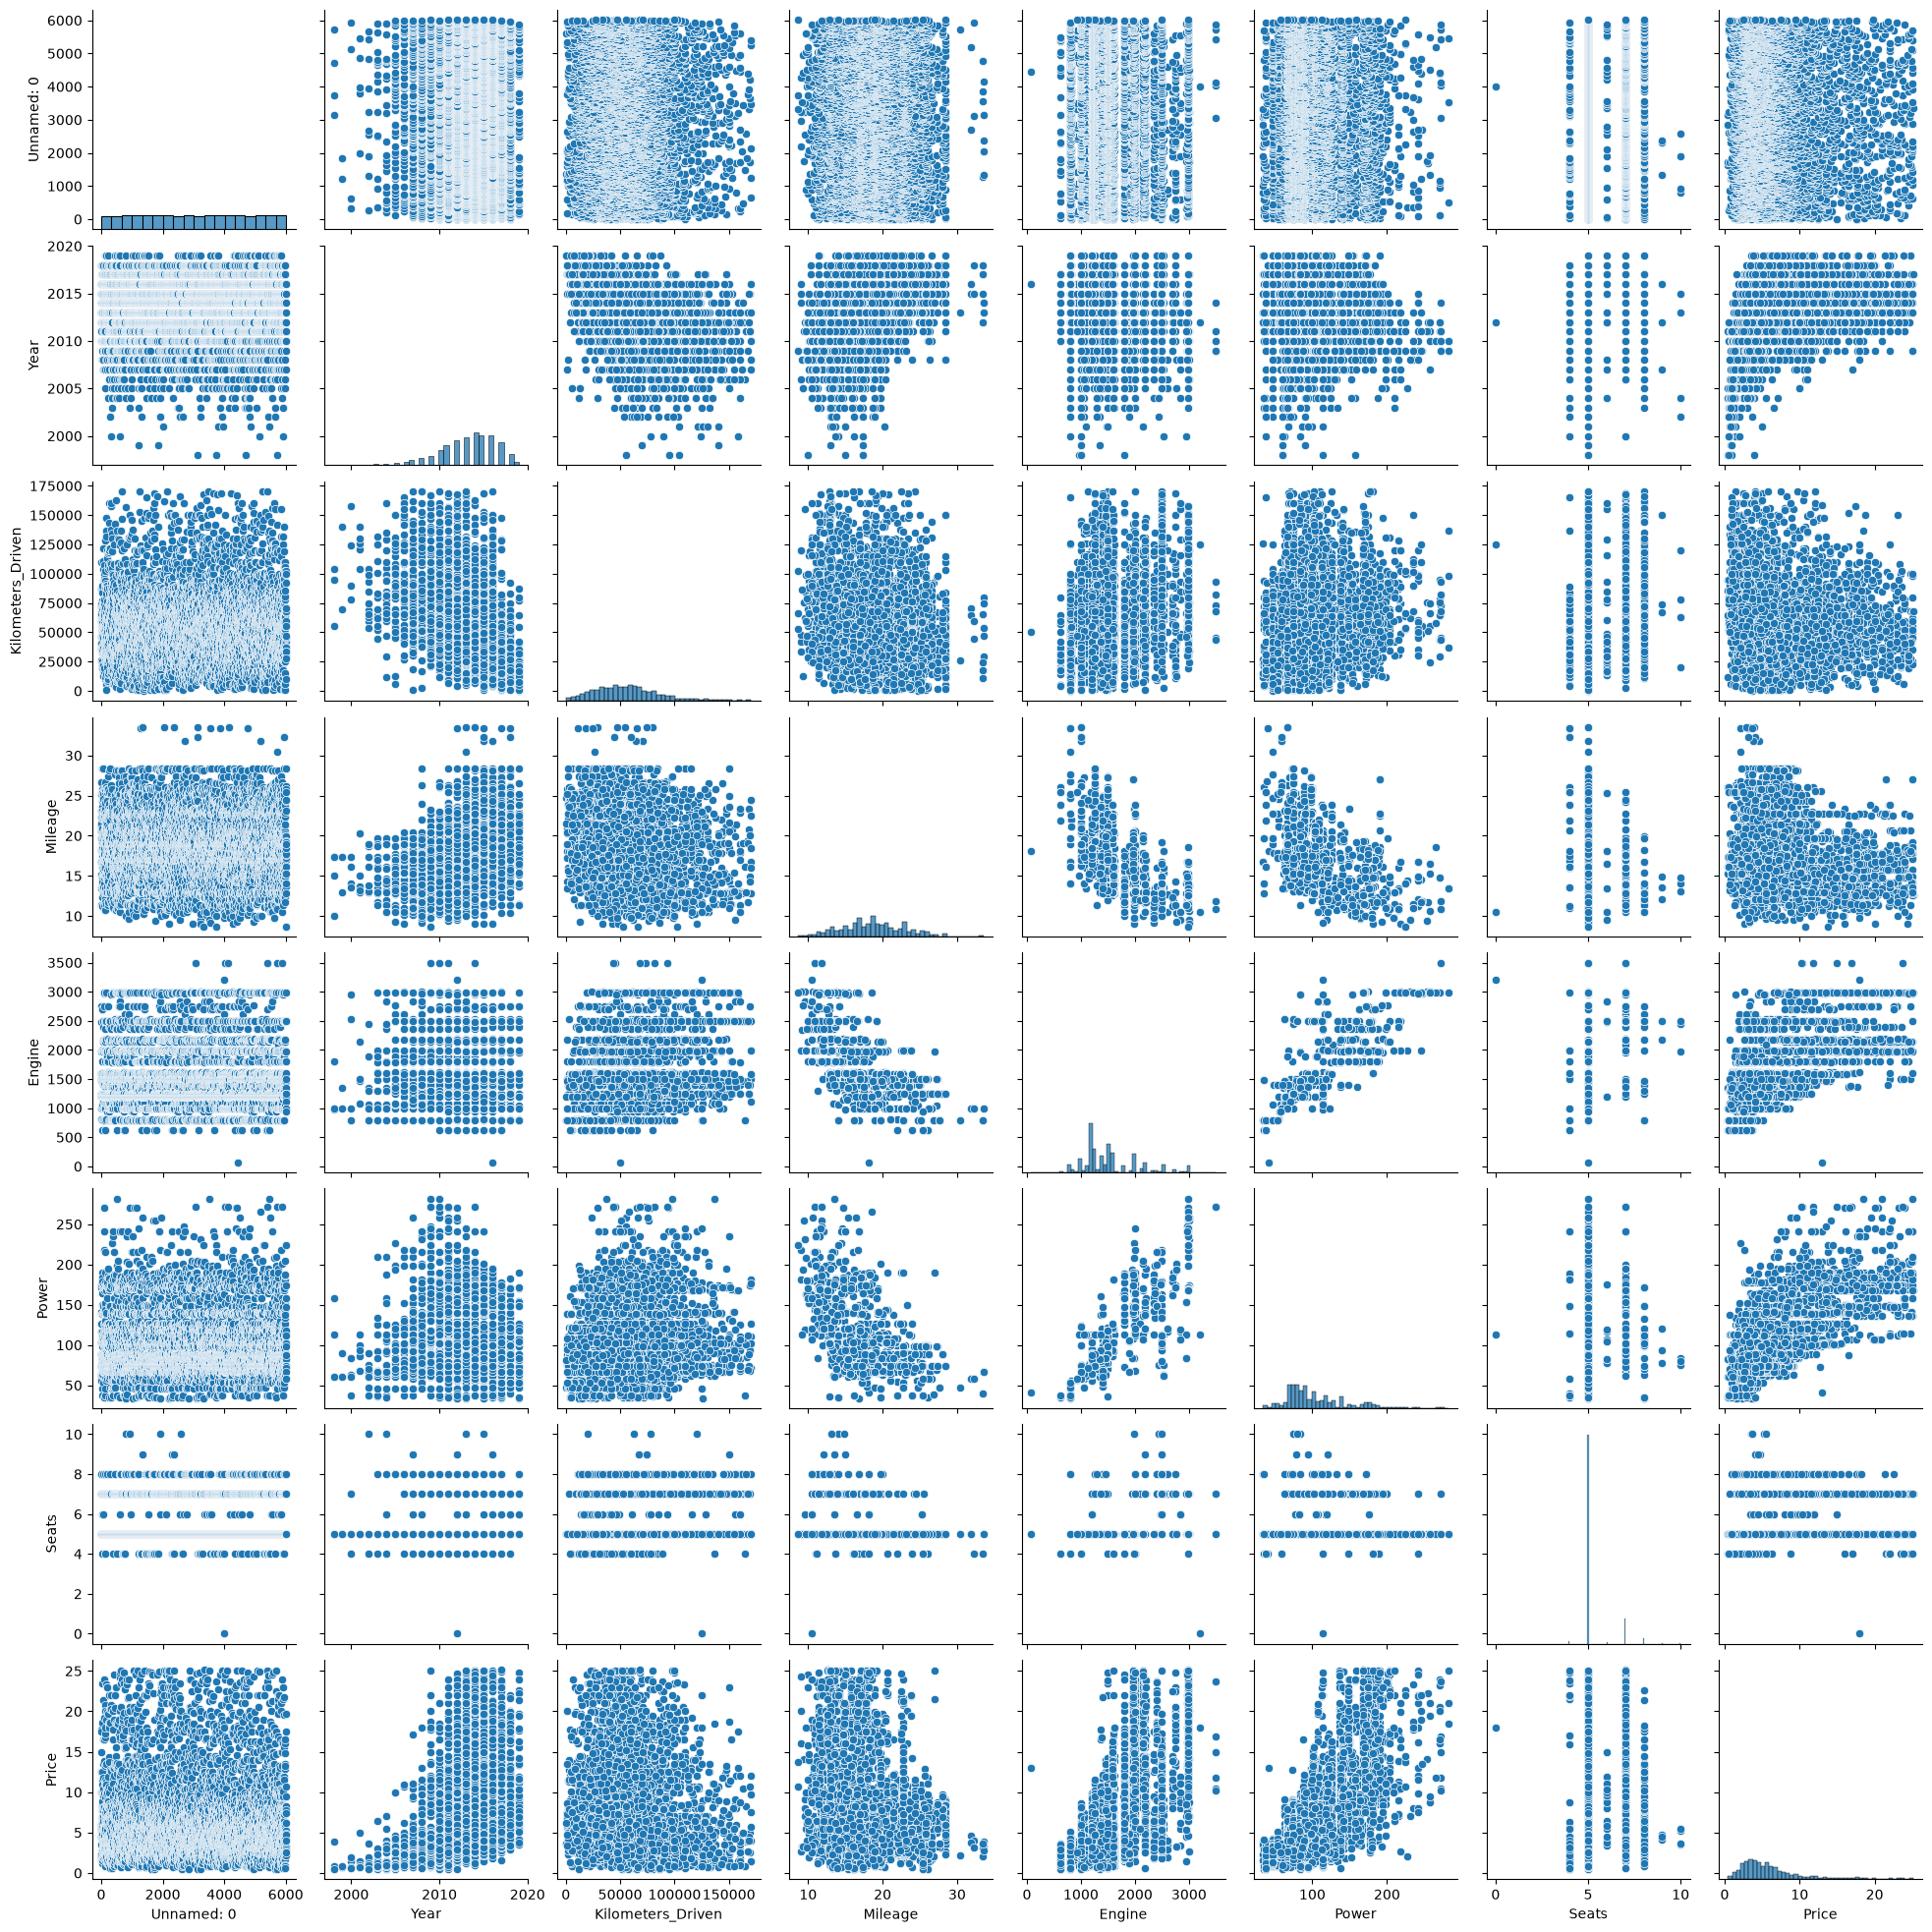

In [35]:
#pair plot
sns.pairplot(df)
plt.show()

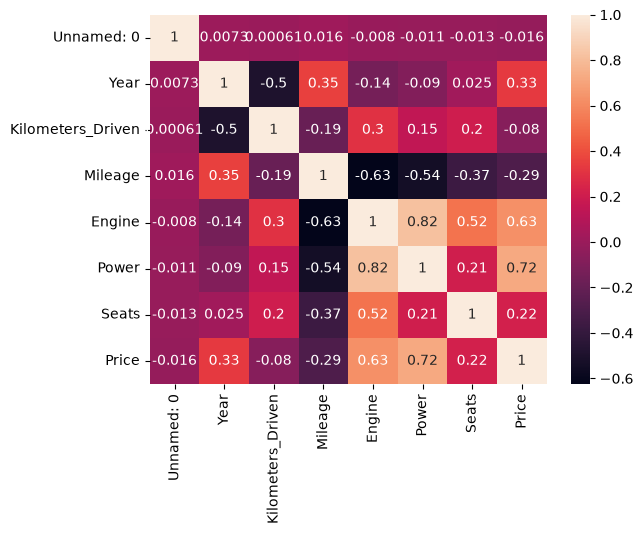

In [36]:
#plotting correlation heatmap for numeric columns
corr_mat=df.corr(numeric_only=True)
corr_mat
sns.heatmap(corr_mat, annot=True)
plt.show()

### **Encoding Categorical Features**

In [37]:
#one hot encoding
df = pd.get_dummies(df,
                         columns = ["Manufacturer", "Fuel_Type", "Transmission", "Location"],
                         drop_first = True,dtype=int)
df.head()

,Unnamed: 0,Name,Year,Kilometers_Driven,Owner_Type,Mileage,Engine,Power,Seats,Price,...,Location_Bangalore,Location_Chennai,Location_Coimbatore,Location_Delhi,Location_Hyderabad,Location_Jaipur,Location_Kochi,Location_Kolkata,Location_Mumbai,Location_Pune
0,0,Maruti Wagon R LXI CNG,2010,72000,First,26.60,998.0,58.16,5.0,1.75,...,0,0,0,0,0,0,0,0,1,0
1,1,Hyundai Creta 1.6 CRDi SX Option,2015,41000,First,19.67,1582.0,126.20,5.0,12.50,...,0,0,0,0,0,0,0,0,0,1
2,2,Honda Jazz V,2011,46000,First,18.20,1199.0,88.70,5.0,4.50,...,0,1,0,0,0,0,0,0,0,0
3,3,Maruti Ertiga VDI,2012,87000,First,20.77,1248.0,88.76,7.0,6.00,...,0,1,0,0,0,0,0,0,0,0
4,4,Audi A4 New 2.0 TDI Multitronic,2013,40670,Second,15.20,1968.0,140.80,5.0,17.74,...,0,0,1,0,0,0,0,0,0,0


In [38]:
#ordinal encoding the owner Type

owner_map = {'First':1, 'Second':2, 'Third':3, 'Fourth & Above':4}
df['Owner_Type'] = df['Owner_Type'].map(owner_map)
df.head()

,Unnamed: 0,Name,Year,Kilometers_Driven,Owner_Type,Mileage,Engine,Power,Seats,Price,...,Location_Bangalore,Location_Chennai,Location_Coimbatore,Location_Delhi,Location_Hyderabad,Location_Jaipur,Location_Kochi,Location_Kolkata,Location_Mumbai,Location_Pune
0,0,Maruti Wagon R LXI CNG,2010,72000,1,26.60,998.0,58.16,5.0,1.75,...,0,0,0,0,0,0,0,0,1,0
1,1,Hyundai Creta 1.6 CRDi SX Option,2015,41000,1,19.67,1582.0,126.20,5.0,12.50,...,0,0,0,0,0,0,0,0,0,1
2,2,Honda Jazz V,2011,46000,1,18.20,1199.0,88.70,5.0,4.50,...,0,1,0,0,0,0,0,0,0,0
3,3,Maruti Ertiga VDI,2012,87000,1,20.77,1248.0,88.76,7.0,6.00,...,0,1,0,0,0,0,0,0,0,0
4,4,Audi A4 New 2.0 TDI Multitronic,2013,40670,2,15.20,1968.0,140.80,5.0,17.74,...,0,0,1,0,0,0,0,0,0,0


### **Feature Selection**

Dropping the 1st Column as it is of no use

In [39]:
#Dropping the 1st column 
df = df.drop(columns='Unnamed: 0')
df.head()

,Name,Year,Kilometers_Driven,Owner_Type,Mileage,Engine,Power,Seats,Price,Manufacturer_Audi,...,Location_Bangalore,Location_Chennai,Location_Coimbatore,Location_Delhi,Location_Hyderabad,Location_Jaipur,Location_Kochi,Location_Kolkata,Location_Mumbai,Location_Pune
0,Maruti Wagon R LXI CNG,2010,72000,1,26.60,998.0,58.16,5.0,1.75,0,...,0,0,0,0,0,0,0,0,1,0
1,Hyundai Creta 1.6 CRDi SX Option,2015,41000,1,19.67,1582.0,126.20,5.0,12.50,0,...,0,0,0,0,0,0,0,0,0,1
2,Honda Jazz V,2011,46000,1,18.20,1199.0,88.70,5.0,4.50,0,...,0,1,0,0,0,0,0,0,0,0
3,Maruti Ertiga VDI,2012,87000,1,20.77,1248.0,88.76,7.0,6.00,0,...,0,1,0,0,0,0,0,0,0,0
4,Audi A4 New 2.0 TDI Multitronic,2013,40670,2,15.20,1968.0,140.80,5.0,17.74,1,...,0,0,1,0,0,0,0,0,0,0


In [40]:
#Dropping the column 'Name'
df = df.drop(columns='Name')
df.head()

,Year,Kilometers_Driven,Owner_Type,Mileage,Engine,Power,Seats,Price,Manufacturer_Audi,Manufacturer_BMW,...,Location_Bangalore,Location_Chennai,Location_Coimbatore,Location_Delhi,Location_Hyderabad,Location_Jaipur,Location_Kochi,Location_Kolkata,Location_Mumbai,Location_Pune
0,2010,72000,1,26.60,998.0,58.16,5.0,1.75,0,0,...,0,0,0,0,0,0,0,0,1,0
1,2015,41000,1,19.67,1582.0,126.20,5.0,12.50,0,0,...,0,0,0,0,0,0,0,0,0,1
2,2011,46000,1,18.20,1199.0,88.70,5.0,4.50,0,0,...,0,1,0,0,0,0,0,0,0,0
3,2012,87000,1,20.77,1248.0,88.76,7.0,6.00,0,0,...,0,1,0,0,0,0,0,0,0,0
4,2013,40670,2,15.20,1968.0,140.80,5.0,17.74,1,0,...,0,0,1,0,0,0,0,0,0,0


### **Standardization**

In [41]:
from sklearn.preprocessing import StandardScaler

In [42]:
# Standardization (mean = 0, standard deviation = 1)
scaler = StandardScaler()
df = pd.DataFrame(scaler.fit_transform(df), columns=df.columns)
df.head()

,Year,Kilometers_Driven,Owner_Type,Mileage,Engine,Power,Seats,Price,Manufacturer_Audi,Manufacturer_BMW,...,Location_Bangalore,Location_Chennai,Location_Coimbatore,Location_Delhi,Location_Hyderabad,Location_Jaipur,Location_Kochi,Location_Kolkata,Location_Mumbai,Location_Pune
0,-1.018201,0.487510,-0.449093,1.933949,-1.059291,-1.145888,-0.355551,-0.992382,-0.163129,-0.17017,...,-0.238636,-0.295966,-0.321513,-0.320812,-0.373754,-0.280133,-0.346183,-0.325007,2.537596,-0.346183
1,0.540912,-0.529214,-0.449093,0.239537,0.109445,0.582907,-0.355551,1.130461,-0.163129,-0.17017,...,-0.238636,-0.295966,-0.321513,-0.320812,-0.373754,-0.280133,-0.346183,-0.325007,-0.394074,2.888649
2,-0.706378,-0.365226,-0.449093,-0.119884,-0.657038,-0.369912,-0.355551,-0.449329,-0.163129,-0.17017,...,-0.238636,3.378771,-0.321513,-0.320812,-0.373754,-0.280133,-0.346183,-0.325007,-0.394074,-0.346183
3,-0.394556,0.979473,-0.449093,0.508491,-0.558976,-0.368387,2.244762,-0.153118,-0.163129,-0.17017,...,-0.238636,3.378771,-0.321513,-0.320812,-0.373754,-0.280133,-0.346183,-0.325007,-0.394074,-0.346183
4,-0.082733,-0.540037,1.745978,-0.853396,0.881931,0.953871,-0.355551,2.165223,6.130136,-0.17017,...,-0.238636,-0.295966,3.110291,-0.320812,-0.373754,-0.280133,-0.346183,-0.325007,-0.394074,-0.346183


## **Splitting Dataset**

In [43]:
from sklearn.model_selection import train_test_split

In [44]:
#separate input and target attributes 
X = df.drop("Price", axis=1)
Y = df["Price"]


In [45]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

## **Model Training and Selection**

In [46]:
from sklearn.linear_model import LinearRegression

In [47]:
# Create model instance
model = LinearRegression()

In [48]:
# Fit the model
model.fit(X_train, Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](48,)","[ 0.38,-0.08,-0.02,...,-0.08,-0.03,-0.01]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](48,)","['Year','Kilometers_Driven','Owner_Type',...,'Location_Kolkata', 'Location_Mumbai','Location_Pune']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.0008751
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,48
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(47)


## **Model Evaluation**

In [49]:
from sklearn.metrics import r2_score

In [50]:
Y_pred = model.predict(X_test)
r2_score(Y_test, Y_pred)

0.8185122712873873